# Descriptive Trend Research — `nq1@1d`

**Question (descriptive, not predictive):** how well does each trend signal — across families and parametrizations — *describe the current trend regime*? Which describe it best, how should we **aggregate** them, and what single 'trend' reading should we **report** per instrument for the universe scan?

We deliberately do **not** use forward returns or fit anything to them (that is the predictive layer, which for trend returned *no edge*). Here the target is the *state* itself. Plan: **(1)** define the regime we're describing → **(2)** lay out the signal panel → **(3)** score each signal's *description* of the regime → **(4)** aggregate → **(5)** decide what to report.

In [1]:
import sys
sys.path[:0] = ['C:\\Users\\SamuelAhou\\Documents\\operator', 'C:\\Users\\SamuelAhou\\Documents\\operator\\research\\trend']
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import descriptive_lib as D
from src.signals import state
SPEC = {'label': 'nq1@1d', 'kind': 'continuous', 'source': 'cme', 'symbol': 'nq', 'timeframe': '1d'}
price = D.load_price(SPEC)
regime = D.reference_regime(price)
panel = D.signal_panel(price)
print(f"{SPEC['symbol']} {SPEC['timeframe']}: {len(price)} bars "
      f"{price.index.min().date()} -> {price.index.max().date()}")

nq 1d: 2180 bars 2019-06-23 -> 2026-06-21


## Step 1 — Define the regime we are describing

Before asking *how well a signal describes the trend*, we need a **reference label** of what the trend actually was. We label each bar from price geometry over a **window centered on it** (≈2 months): the **direction** is the sign of the net move across the window, and the **efficiency ratio** (net move ÷ path length, 0–1) says how cleanly it trended.

To avoid a label that *flickers* (a naive `er ≥ threshold` toggles on every wiggle), the rule has two pieces of memory: **hysteresis** — *enter* a trend at `er ≥ 0.25` but *stay* in it until `er < 0.12`, so a pullback inside a trend doesn't drop to chop; and a **minimum regime length** — runs shorter than ~30 bars (≈6 weeks) are absorbed into their longer neighbour, removing short chop islands inside trends. The result is contiguous regimes (`up_trend`/`down_trend`/`chop`).

Because the window is *centered*, this uses future bars — it is deliberate **hindsight 'ground truth'** for benchmarking, **never a tradeable signal**. Everything we score against it (the signals) is strictly causal.

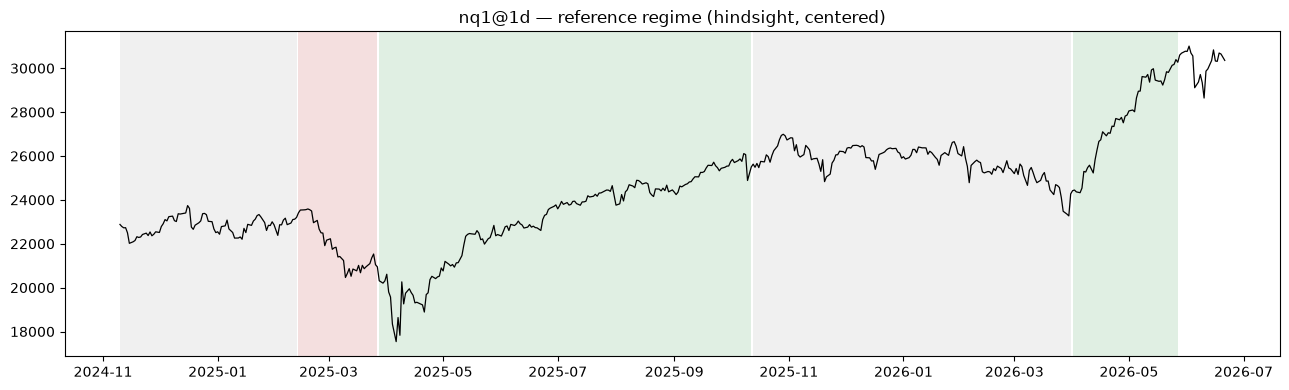

regime
chop          1259
up_trend       763
down_trend     115
None            43
Name: count, dtype: int64

In [2]:
D.plot_regime(price, regime, f"{SPEC['label']} — reference regime (hindsight, centered)")
regime['regime'].value_counts(dropna=False)

## Step 2 — The signal panel (families × parametrizations)

Four causal families, each at several speeds: **EWMAC** crossovers (8/32 … 64/256), **TSMOM** (32 … 256), **regression slope-t** (32 … 128), **Carver breakout** (64, 128). All vol-normalized; the **sign** is the called direction, the **magnitude** is strength. Below, a fast / medium / slow example under the regime shading — note how fast signals flip with every wiggle while slow ones lag the turns.

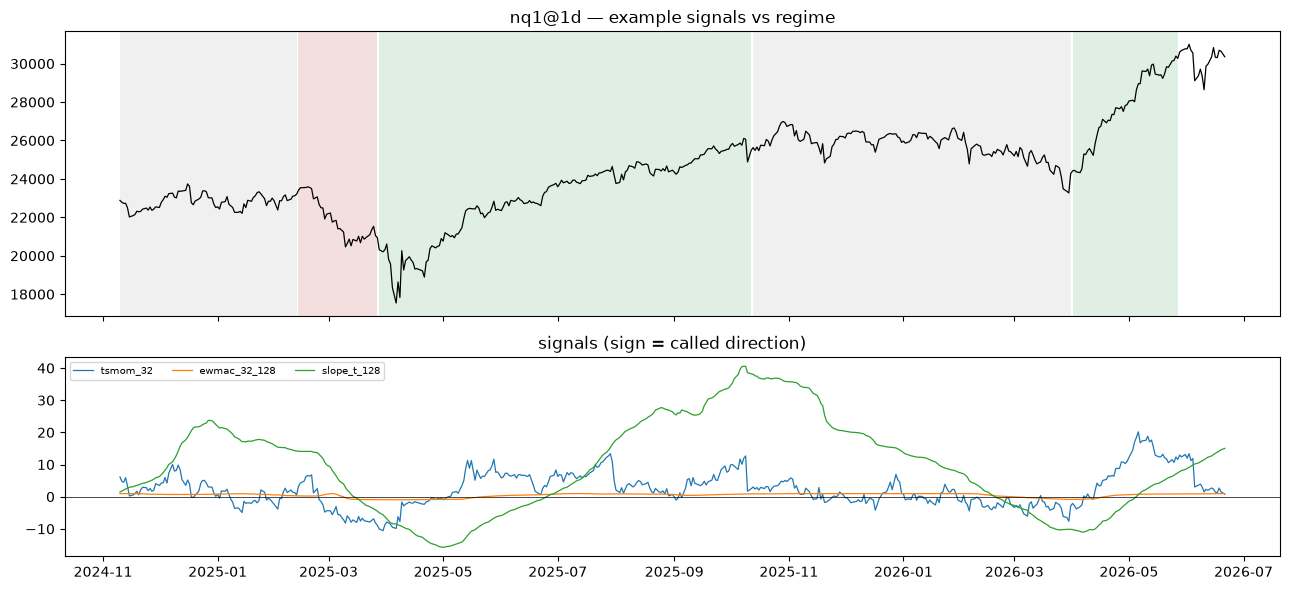

In [3]:
D.plot_signal_examples(price, panel, regime,
    ['tsmom_32', 'ewmac_32_128', 'slope_t_128'],
    f"{SPEC['label']} — example signals vs regime")

## Step 3 — How well does each signal *describe* the regime?

Four descriptive metrics (no forward returns anywhere):
- **direction agreement** — on trending bars, how often `sign(signal)` matches the regime direction (concurrent hit-rate; 0.5 = coin flip).
- **trend/chop discrimination (AUC)** — does `|signal|` run larger in trends than in chop? (0.5 = no separation, 1 = perfect.)
- **lag** — median bars from a regime turn to the signal reflecting it (timeliness).
- **flip-rate** — how often the signal's sign changes (stability; high = whippy).

In [4]:
scores = D.score_panel(panel, regime)
scores.round(3).sort_values('dir_agreement', ascending=False)

,dir_agreement,trendchop_auc,lag_bars,flip_rate
ewmac_8_32,0.936,0.657,2.0,0.032
breakout_64,0.909,0.720,2.0,0.058
ewmac_16_64,0.897,0.658,5.0,0.019
breakout_128,0.878,0.702,4.0,0.033
tsmom_32,0.877,0.743,2.5,0.067
slope_t_32,0.877,0.730,6.0,0.028
tsmom_64,0.855,0.693,2.0,0.043
tsmom_256,0.854,0.432,0.0,0.013
ewmac_32_128,0.848,0.561,29.0,0.006
tsmom_128,0.822,0.521,13.0,0.021


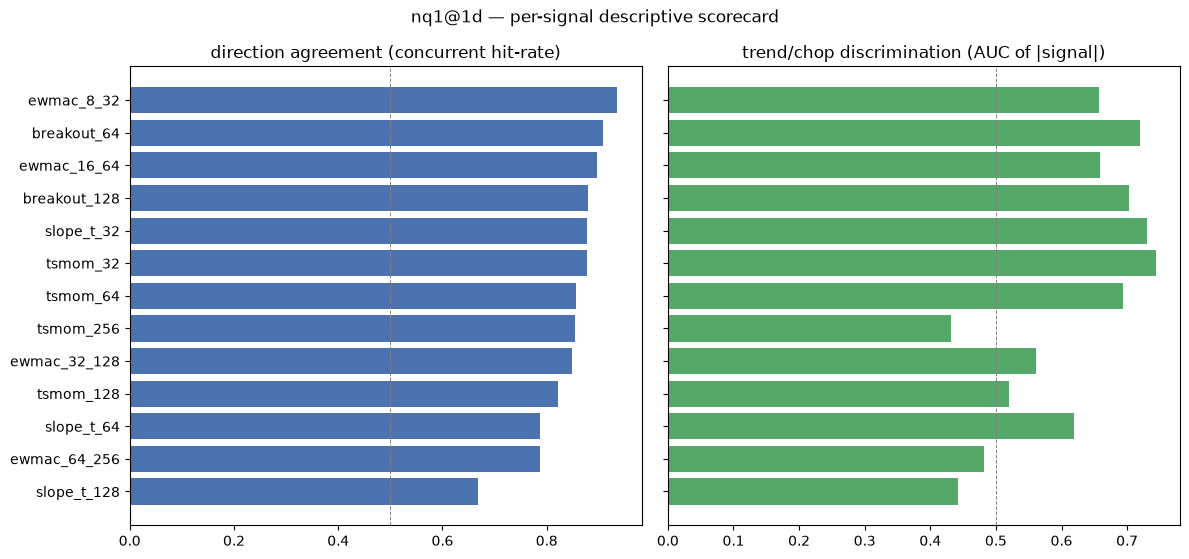

In [5]:
D.plot_scorecard(scores, f"{SPEC['label']} — per-signal descriptive scorecard")

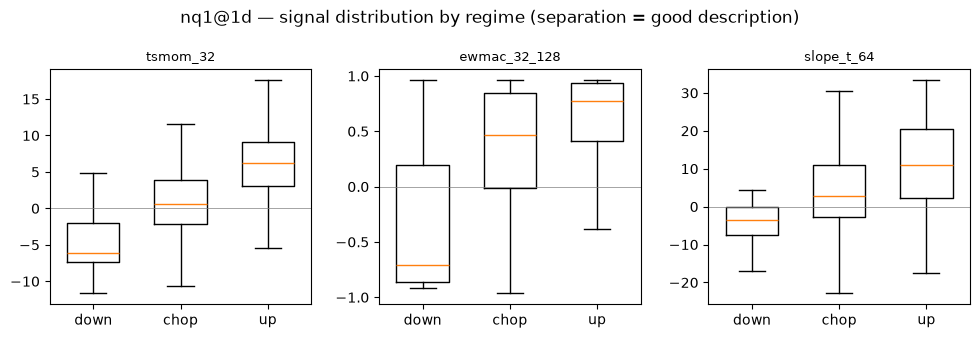

In [6]:
D.plot_conditional(panel, regime, ['tsmom_32', 'ewmac_32_128', 'slope_t_64'],
    f"{SPEC['label']} — signal distribution by regime (separation = good description)")

**What this shows.** A clear **timeliness ↔ stability trade-off**: *fast* signals (e.g. `tsmom_32`, `slope_t_32`) win on direction agreement and react in 1–3 bars but flip often (noisy description); *slow* signals are very stable but lag the turns by weeks and can even lose trend/chop separation. No single parametrization is both timely *and* stable — which motivates aggregating across speeds.

## Step 4 — How should we aggregate the family?

Three ways to collapse the panel into **one** trend descriptor: **`mean_z`** (mean of causally-standardized signals — direction + strength), **`vote`** (net sign consensus, −1…1), **`pca1`** (first principal component; whole-sample fit, so descriptive). We score the aggregates with the *same* metrics and compare to the best single signal.

In [7]:
agg = D.aggregates(panel)
agg_scores = D.score_panel(agg, regime)
agg_scores.round(3)

,dir_agreement,trendchop_auc,lag_bars,flip_rate
mean_z,0.876,0.671,7.0,0.028
vote,0.875,0.665,6.5,0.030
pca1,0.870,0.583,5.0,0.024


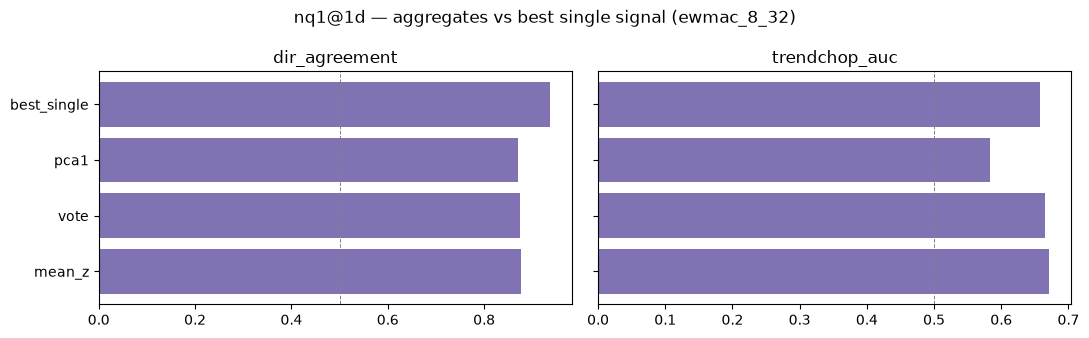

In [8]:
best = scores['dir_agreement'].idxmax()
D.plot_aggregate_comparison(agg_scores, scores.loc[best],
    f"{SPEC['label']} — aggregates vs best single signal ({best})")

**What this shows.** **`mean_z`** is the best all-rounder: top **trend/chop discrimination**, near-top **direction agreement**, and **stable** (low flip-rate) with only moderate lag — it keeps the fast signals' direction sense while averaging out their whipsaw. It is the natural quantity to report. (`vote` is a clean direction-only summary; `pca1` mostly re-discovers `mean_z` but is less interpretable.)

## Step 5 — What we report for the universe scan

The reading we surface per instrument is the **causal** version of the winning aggregate (`src.signals.state.trend_state`): a **direction**, a **strength** and — crucially — that strength's **percentile within the instrument's own history** (*is this trend unusually strong right now?*), plus cross-scale **agreement**, the efficiency ratio, and the live **regime** label. This study is what justifies that construction: the aggregate faithfully reproduces the hindsight regime, with a known (reportable) lag. Here is the current snapshot:

In [9]:
live = state.current_state(state.trend_state(price))
print(f"as of {price.index.max().date()}")
print(f"  regime         : {live['regime']}")
print(f"  direction      : {int(live['dir']):+d}")
print(f"  intensity      : {live['intensity']:.2f}  "
      f"(history %ile: {live['intensity_pct']:.0%})")
print(f"  scale agreement: {live['agree']:.0%}")
print(f"  efficiency     : {live['er']:.2f}")
print(f"  slope t-stat   : {live['slope_t']:+.1f}")

as of 2026-06-21
  regime         : chop
  direction      : +1
  intensity      : 0.65  (history %ile: 31%)
  scale agreement: 100%
  efficiency     : 0.29
  slope t-stat   : +15.1


## Summary

Descriptive findings for this instrument:
1. **No single speed is best** — fast = timely but whippy, slow = stable but laggy.
2. **`mean_z` aggregation** describes the regime best overall (discrimination + agreement + stability), so the reported trend reading is a multi-scale aggregate.
3. We report **direction + strength + historical percentile + agreement + regime** — a compact, comparable state line for the universe scan.

> Descriptive — *characterizes the current trend state, not tradeability.*

*Next:* run this same study on the rest of the universe (es1, nq1, eth) and roll the per-instrument readings into the cross-sectional **universe scan**; then repeat the pattern for mean-reversion and support/resistance.